<a href="https://colab.research.google.com/github/Ayesh2002/ml-student-dropout/blob/logistic-regression/01_logistic_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#1. Data Exploration and Preprocessing Plan

### 1.1 Dataset Overview

In [1]:
import pandas as pd
url = "https://raw.githubusercontent.com/Ayesh2002/ml-student-dropout/main/data/student_dropout_academic_.csv"
df = pd.read_csv(url)
df.shape

(4424, 37)

### 1.2 Target Distribution

In [20]:
df.info()
print(df["Target"].value_counts())
df.describe().T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance                      4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4424 non-null   float64
 7   Nationality                                     4424 non-null   int64  
 8   Mother's qualification                          4424 non-null   int64  
 9   Father's qualification                   

,count,mean,std,min,25%,50%,75%,max
Marital status,4424.0,1.178571,0.605747,1.00,1.00,1.000000,1.000000,6.000000
Application mode,4424.0,18.669078,17.484682,1.00,1.00,17.000000,39.000000,57.000000
Application order,4424.0,1.727848,1.313793,0.00,1.00,1.000000,2.000000,9.000000
Course,4424.0,8856.642631,2063.566416,33.00,9085.00,9238.000000,9556.000000,9991.000000
Daytime/evening attendance,4424.0,0.890823,0.311897,0.00,1.00,1.000000,1.000000,1.000000
Previous qualification,4424.0,4.577758,10.216592,1.00,1.00,1.000000,1.000000,43.000000
Previous qualification (grade),4424.0,132.613314,13.188332,95.00,125.00,133.100000,140.000000,190.000000
Nationality,4424.0,1.873192,6.914514,1.00,1.00,1.000000,1.000000,109.000000
Mother's qualification,4424.0,19.561935,15.603186,1.00,2.00,19.000000,37.000000,44.000000
Father's qualification,4424.0,22.275316,15.343108,1.00,3.00,19.000000,37.000000,44.000000


### 1.3 Feature Type Identification
In the first semester, 718 students have a grade of zero. For 349 of them, the number of evaluations is also zero, which suggests they were not assessed. The remaining 369 students were evaluated but recorded a grade of zero. The dataset does not explain this, so these values may reflect failed assessments or missing grades entered as zero. We treat grades as numeric in the model, which means these zeros are interpreted as low scores. This is a limitation of the grade features.


In [21]:
pd.crosstab(df["Curricular units 1st sem (grade)"] == 0,
            df["Curricular units 1st sem (evaluations)"] == 0)

Curricular units 1st sem (evaluations),False,True
Curricular units 1st sem (grade),,
False,3706,0
True,369,349


In [4]:
df.nunique().sort_values()

,0
Daytime/evening attendance,2
Displaced,2
Debtor,2
Educational special needs,2
International,2
Scholarship holder,2
Gender,2
Tuition fees up to date,2
Target,3
Marital status,6


### 1.4 Rare Category Analysis

In [5]:
for col in ["Nationality", "Mother's occupation", "Father's occupation", "Application mode"]:
    print(col, df[col].value_counts().head(10).to_dict())

Nationality {1: 4314, 41: 38, 26: 14, 6: 13, 22: 13, 24: 5, 100: 3, 11: 3, 103: 3, 62: 2}
Mother's occupation {9: 1577, 4: 817, 5: 530, 3: 351, 2: 318, 7: 272, 0: 144, 1: 102, 6: 91, 90: 70}
Father's occupation {9: 1010, 7: 666, 5: 516, 4: 386, 3: 384, 8: 318, 10: 266, 6: 242, 2: 197, 1: 134}
Application mode {1: 1708, 17: 872, 39: 785, 43: 312, 44: 213, 7: 139, 18: 124, 42: 77, 51: 59, 16: 38}


## 2. Preprocessing Pipeline

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Separate features from the target
X = df.drop(columns="Target")
y = df["Target"]

# Stratified split keeps the class proportions the same in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# Column groups, based on the unique-value analysis
binary_cols = [
    "Daytime/evening attendance", "Displaced", "Debtor",
    "Educational special needs", "International",
    "Scholarship holder", "Gender", "Tuition fees up to date",
]

categorical_cols = [
    "Marital status", "Application order", "Course",
    "Previous qualification", "Application mode", "Nationality",
    "Mother's qualification", "Father's qualification",
    "Mother's occupation", "Father's occupation",
]

# Everything else is numeric: grades, counts, age, and macroeconomic values
numeric_cols = [c for c in X.columns if c not in binary_cols + categorical_cols]

# Rare categories (fewer than 30 training rows) are grouped into one
# "infrequent" level, learned from the training data only
preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(min_frequency=30,
                              handle_unknown="infrequent_if_exist",
                              sparse_output=False), categorical_cols),
        ("num", StandardScaler(), numeric_cols),
        ("bin", "passthrough", binary_cols),
    ]
)

# Fit on training data only, then apply the same transformation to the test set
X_train_p = preprocessor.fit_transform(X_train)
X_test_p = preprocessor.transform(X_test)

print("Training shape:", X_train_p.shape)
print("Test shape:", X_test_p.shape)
print("\nTrain class proportions:\n", y_train.value_counts(normalize=True).round(3))
print("\nTest class proportions:\n", y_test.value_counts(normalize=True).round(3))

Training shape: (3539, 120)
Test shape: (885, 120)

Train class proportions:
 Target
Graduate    0.499
Dropout     0.321
Enrolled    0.179
Name: proportion, dtype: float64

Test class proportions:
 Target
Graduate    0.499
Dropout     0.321
Enrolled    0.180
Name: proportion, dtype: float64


## 3. Model Selection: Logistic Regression
We use multinomial logistic regression to predict the three outcome classes: Graduate, Dropout, and Enrolled. Logistic regression models the probability of each class as a softmax function of a weighted sum of the input features. It was chosen because it produces class probabilities,its coefficients can be interpreted directly, and it provides a transparent baseline against which the random forest can be compared (Cox, 1958; Hosmer et al., 2013).

The target is moderately imbalanced. Graduate accounts for 2,209 of 4,424 records (about 50%), Dropout for 1,421 (about 32%), and Enrolled for 794 (about 18%). A model that ignores the minority class could still achieve around 50% accuracy by predicting Graduate for every student. To counter this, we set `class_weight="balanced"`, which scales each class's contribution to the loss inversely to its frequency. This makes errors on the Enrolled class count more heavily during training, so the model is less likely to favour the majority classes. The effect is evaluated with macro-averaged F1 and per-class recall rather than accuracy alone.


Accuracy: 0.7299
Macro F1: 0.6927

              precision    recall  f1-score   support

     Dropout       0.82      0.69      0.75       284
    Enrolled       0.42      0.64      0.50       159
    Graduate       0.87      0.79      0.83       442

    accuracy                           0.73       885
   macro avg       0.70      0.70      0.69       885
weighted avg       0.77      0.73      0.74       885



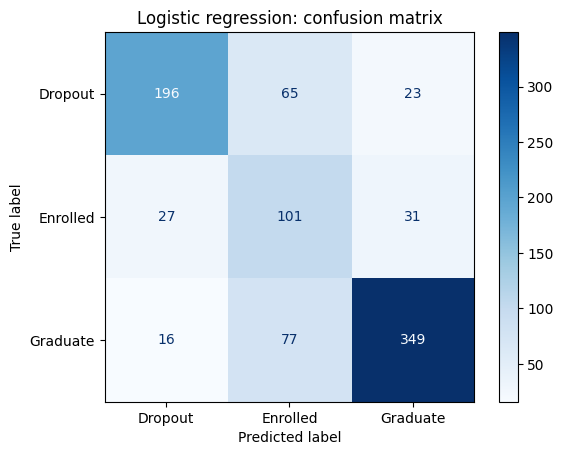

In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)
import matplotlib.pyplot as plt

# class_weight="balanced" makes the model pay more attention to the
# minority Enrolled class, which is important with this target distribution
model = LogisticRegression(
    solver="lbfgs",
    max_iter=1000,
    class_weight="balanced",
    random_state=42,
)
model.fit(X_train_p, y_train)
y_pred = model.predict(X_test_p)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Macro F1:", round(f1_score(y_test, y_pred, average="macro"), 4))
print()
print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred, labels=model.classes_)
ConfusionMatrixDisplay(cm, display_labels=model.classes_).plot(cmap="Blues")
plt.title("Logistic regression: confusion matrix")
plt.show()

### 3.1 Unweighted Baseline Comparison

To measure the effect of `class_weight="balanced"`, we trained a second logistic regression model with the same settings but without class weighting. Both models use the same preprocessed training data and are evaluated on the same test set of 885 students.

The unweighted model achieves an accuracy of 0.77 and a macro-averaged F1-score of 0.70. Its Graduate class is predicted with high recall (0.92), but its Enrolled class recall falls to 0.42, meaning many Enrolled students are misclassified as Graduate or Dropout. The weighted model from Section 3 reaches an accuracy of 0.73 and a macro-F1 of 0.69, with Enrolled recall of 0.64 and precision of 0.42.

The two models therefore represent different trade-offs. The unweighted model is more accurate overall, while the weighted model identifies more Enrolled students at the cost of precision. Because this comparison was made on the test set, it is treated as exploratory. The final model is selected using cross-validation on the training data, as described in Section 3.2.

In [8]:
model_nw = LogisticRegression(solver="lbfgs", max_iter=1000, random_state=42)
model_nw.fit(X_train_p, y_train)
y_pred_nw = model_nw.predict(X_test_p)

print("Accuracy:", round(accuracy_score(y_test, y_pred_nw), 4))
print("Macro F1:", round(f1_score(y_test, y_pred_nw, average="macro"), 4))
print(classification_report(y_test, y_pred_nw))

Accuracy: 0.7729
Macro F1: 0.7026
              precision    recall  f1-score   support

     Dropout       0.79      0.75      0.77       284
    Enrolled       0.55      0.42      0.47       159
    Graduate       0.81      0.92      0.86       442

    accuracy                           0.77       885
   macro avg       0.72      0.69      0.70       885
weighted avg       0.76      0.77      0.76       885



### 3.2 Hyperparameter Tuning with Cross-validation

To select the final configuration without relying on the test set, we tuned the regularisation strength C (0.01, 0.1, 1, 10) and the class weighting (none or balanced) using 5-fold stratified cross-validation on the training data, optimising macro-averaged F1. Also the preprocessing steps were included inside the pipeline, so they were refitted within each fold and no validation data influenced the encoding or scaling.

The best configuration was C = 0.1 with class_weight="balanced", achieving a cross-validated macro-F1 of 0.71. Among the values tested, this stronger regularisation performed best, as a result this suggests that constraining the 120 coefficients reduces overfitting to the training data.



In [9]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold

pipe = Pipeline([
    ("prep", preprocessor),
    ("clf", LogisticRegression(solver="lbfgs", max_iter=5000, random_state=42)),
])

param_grid = {
    "clf__C": [0.01, 0.1, 1, 10],
    "clf__class_weight": [None, "balanced"],
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
search = GridSearchCV(pipe, param_grid, cv=cv, scoring="f1_macro", n_jobs=-1)
search.fit(X_train, y_train)

print("Best parameters:", search.best_params_)
print("Best cross-validated macro F1:", round(search.best_score_, 4))

Best parameters: {'clf__C': 0.1, 'clf__class_weight': 'balanced'}
Best cross-validated macro F1: 0.7125


### 3.3 Final Model Evaluation on the Test Set

The model selected in Section 3.2 was evaluated once on the held-out test set of 885 students. It achieved an accuracy of 0.73 and a macro-F1 of 0.69. The Graduate class has the highest recall (0.80) and precision (0.87). The Enrolled class has the lowest precision (0.41) despite a recall of 0.64, meaning that most students predicted as Enrolled belong to another class. This is the same pattern seen in the earlier comparison, and it is the main weakness of the model.

The test macro-F1 (0.69) is slightly below the cross-validated estimate (0.71). A difference of this size is expected from a single test split, since any one sample of students varies from the average across folds.

The test set was used only in this section. The earlier comparisons in Section 3.1 were also evaluated on the test set, so they are treated as exploratory, and the figures reported here are the model's final performance.

In [10]:
best_model = search.best_estimator_
y_pred_best = best_model.predict(X_test)
print("Test accuracy:", round(accuracy_score(y_test, y_pred_best), 4))
print("Test macro F1:", round(f1_score(y_test, y_pred_best, average="macro"), 4))
print(classification_report(y_test, y_pred_best))

Test accuracy: 0.7288
Test macro F1: 0.6909
              precision    recall  f1-score   support

     Dropout       0.82      0.67      0.74       284
    Enrolled       0.41      0.64      0.50       159
    Graduate       0.87      0.80      0.83       442

    accuracy                           0.73       885
   macro avg       0.70      0.70      0.69       885
weighted avg       0.77      0.73      0.74       885



### 3.4 Dimensionality Reduction with PCA

One-hot encoding expands the 36 original features to 120 columns, so we tested whether Principal Component Analysis (PCA) could reduce this without losing predictive performance. PCA was added as a step in the pipeline, and the number of components was selected by 5-fold stratified cross-validation, optimising macro-F1. The regularisation strength and class weighting were fixed to the values selected in Section 3.2, so the only variable was the dimensionality.

Across the tested values of 10, 20, 40, 60, and 80 components, the best result was 80 components, with a cross-validated macro-F1 of 0.713. This is effectively identical to the 120-feature model in Section 3.2, which scored 0.7125. Performance increased as the number of components grew and reached the full-model level only at the largest value tested. This suggests that the predictive information is spread across many components rather than concentrated in a few, so reducing dimensionality does not improve generalisation within the range tested.

Because the reduced model does not outperform the full model, the 120-feature model is retained. Reducing dimensionality would also make the coefficients harder to interpret, since each component is a linear combination of the original features, and that cost is not offset by any gain in performance.

In [11]:
from sklearn.decomposition import PCA

pca_pipe = Pipeline([
    ("prep", preprocessor),
    ("pca", PCA(random_state=42)),
    ("clf", LogisticRegression(solver="lbfgs", max_iter=5000, random_state=42)),
])

pca_grid = {
    "pca__n_components": [10, 20, 40, 60, 80],
    "clf__C": [0.1],
    "clf__class_weight": ["balanced"],
}

pca_search = GridSearchCV(pca_pipe, pca_grid, cv=cv, scoring="f1_macro", n_jobs=-1)
pca_search.fit(X_train, y_train)

print("Best parameters:", pca_search.best_params_)
print("Best cross-validated macro F1 with PCA:", round(pca_search.best_score_, 4))
print("Without PCA (from section 3.2):", round(search.best_score_, 4))

Best parameters: {'clf__C': 0.1, 'clf__class_weight': 'balanced', 'pca__n_components': 80}
Best cross-validated macro F1 with PCA: 0.713
Without PCA (from section 3.2): 0.7125


### 4. Critical Analysis



### 4.1 Interpretation of the Model

The table below lists the eight largest coefficients for each class in the tuned model. Coefficients show how each feature shifts the log-odds of a class relative to the others, so their signs and sizes indicate direction and relative strength. The interpretation follows the output.

In [12]:
import numpy as np
import pandas as pd

# Feature names after preprocessing, e.g. "cat__Course_9238", "num__Admission grade"
feature_names = best_model.named_steps["prep"].get_feature_names_out()
coefs = best_model.named_steps["clf"].coef_   # shape: (3 classes, 120 features)

for i, cls in enumerate(best_model.named_steps["clf"].classes_):
    top = (pd.Series(coefs[i], index=feature_names)
             .sort_values(key=abs, ascending=False)
             .head(8))
    print(f"\nLargest coefficients for {cls}:")
    print(top.round(3).to_string())


Largest coefficients for Dropout:
bin__Tuition fees up to date                  -1.377
num__Curricular units 2nd sem (approved)      -1.294
num__Curricular units 1st sem (approved)      -0.679
num__Curricular units 2nd sem (enrolled)       0.640
cat__Course_9853                               0.578
cat__Father's occupation_infrequent_sklearn   -0.570
cat__Course_9130                               0.516
cat__Mother's occupation_0                     0.462

Largest coefficients for Enrolled:
cat__Course_9119                               0.592
cat__Mother's occupation_0                    -0.574
cat__Mother's occupation_infrequent_sklearn    0.499
cat__Mother's occupation_90                   -0.434
cat__Mother's qualification_34                -0.431
cat__Course_9130                              -0.419
cat__Father's occupation_infrequent_sklearn    0.402
cat__Father's occupation_0                    -0.379

Largest coefficients for Graduate:
num__Curricular units 2nd sem (approved)    1

### 4.2 Verification of Category Counts

Before interpreting the codes with large coefficients, checked how many students each code covers. Codes with very few students would make their coefficients unreliable, so this check confirms that the main Enrolled predictors rest on reasonable sample sizes.

In [13]:
codes_to_check = {
    "Course": [9119, 9130],
    "Mother's occupation": [0, 90],
    "Father's occupation": [0],
    "Mother's qualification": [34],
}

for col, values in codes_to_check.items():
    counts = df[col].value_counts()
    for v in values:
        print(f"{col} = {v}: {counts.get(v, 0)} students")

Course = 9119: 170 students
Course = 9130: 141 students
Mother's occupation = 0: 144 students
Mother's occupation = 90: 70 students
Father's occupation = 0: 128 students
Mother's qualification = 34: 130 students


In [14]:
for col in ["Mother's occupation", "Father's occupation"]:
    counts = df[col].value_counts()
    rare = counts[counts < 30]
    print(f"{col}: {len(rare)} codes with fewer than 30 students, covering {rare.sum()} students")

Mother's occupation: 21 codes with fewer than 30 students, covering 116 students
Father's occupation: 34 codes with fewer than 30 students, covering 112 students



### 4.3 Comparison with Permutation Importance

Coefficients depend on feature scale and can be unstable when features are correlated, so it is also measured how much macro-F1 falls when each original feature is randomly shuffled, averaged over five repeats on the training data. Because this measure is unaffected by units, it provides an independent check on the coefficient ranking.

The two methods agree on the most important features. Second-semester approved units (0.207) and first-semester approved units (0.109) are the largest contributors, followed by tuition fees up to date (0.047), matching their large coefficients in Section 4.1. Second-semester enrolled units (0.042) also rank highly, consistent with its large coefficients, although its sign reversal suggests it is partly redundant with the approval counts.

The comparison also shows a limitation. Several codes with large Enrolled coefficients, including mother's occupation codes 0 and 90, do not appear in the top ten. Course (0.028) and father's occupation (0.014) contribute more modestly. A large coefficient on an individual code therefore does not necessarily mean the code matters much for overall predictive performance. Permutation importance measures overall macro-F1 rather than class-specific performance, so it cannot confirm the Enrolled-specific associations in Section 4.1. Importance values for correlated features are likely to be understated, because shuffling one feature leaves its correlated partners to carry much of the same information.

In [15]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(
    best_model, X_train, y_train,
    scoring="f1_macro", n_repeats=5, random_state=42, n_jobs=-1
)

perm_importance = pd.Series(perm.importances_mean, index=X_train.columns)
print(perm_importance.sort_values(ascending=False).head(10).round(4).to_string())

Curricular units 2nd sem (approved)       0.2073
Curricular units 1st sem (approved)       0.1086
Tuition fees up to date                   0.0469
Curricular units 2nd sem (enrolled)       0.0421
Curricular units 2nd sem (evaluations)    0.0291
Course                                    0.0280
Curricular units 1st sem (enrolled)       0.0170
Curricular units 1st sem (evaluations)    0.0161
Father's occupation                       0.0137
Curricular units 2nd sem (grade)          0.0128


### 4.4 Diagnostic Analysis: ROC and Learning Curves

Two diagnostic plots examine the limits identified above. The ROC curves show how well the model separates each class from the others across all decision thresholds. The learning curve shows how cross-validated performance changes as the amount of training data increases. Both use cross-validation on the training data only, so the test set remains untouched.

Dropout and Graduate both achieve an area under the ROC curve (AUC) of 0.92, indicating strong separation from the other classes. Enrolled achieves 0.82, the lowest of the three, and its curve lies below the others across most thresholds. This supports the claim in Section 4.1 that Enrolled is the hardest class to separate using the features provided. Because each curve compares one class with the rest, AUC reflects separability rather than class size.

The cross-validated macro-F1 rises from about 0.64 when each fold is trained on roughly 280 students to about 0.71 at around 1,800 students per fold, and then levels off at about 0.71 for the largest sizes tested. The training score remains near 0.75 throughout, leaving a gap of roughly 0.04 between training and validation performance, which suggests mild overfitting. Within the sizes tested, the curve flattens after about 1,800 students, so adding data would be unlikely to change performance substantially. This points to the features and the Enrolled label as the more likely limits, consistent with the discussion in Section 4.1.

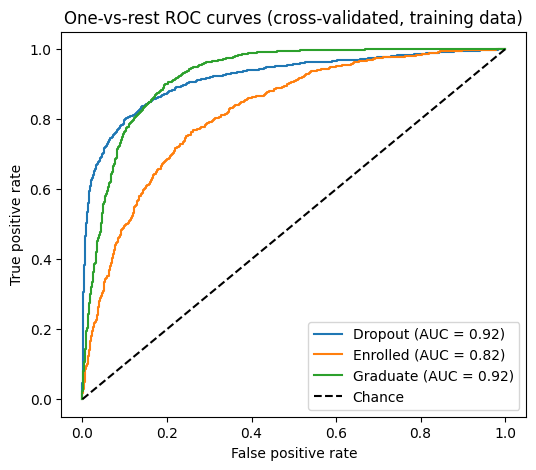

In [16]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize
import matplotlib.pyplot as plt
import numpy as np

classes = best_model.named_steps["clf"].classes_
y_train_bin = label_binarize(y_train, classes=classes)
y_proba_cv = cross_val_predict(best_model, X_train, y_train, cv=cv,
                               method="predict_proba", n_jobs=-1)

plt.figure(figsize=(6, 5))
for i, cls in enumerate(classes):
    fpr, tpr, _ = roc_curve(y_train_bin[:, i], y_proba_cv[:, i])
    plt.plot(fpr, tpr, label=f"{cls} (AUC = {auc(fpr, tpr):.2f})")
plt.plot([0, 1], [0, 1], "k--", label="Chance")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("One-vs-rest ROC curves (cross-validated, training data)")
plt.legend()
plt.show()

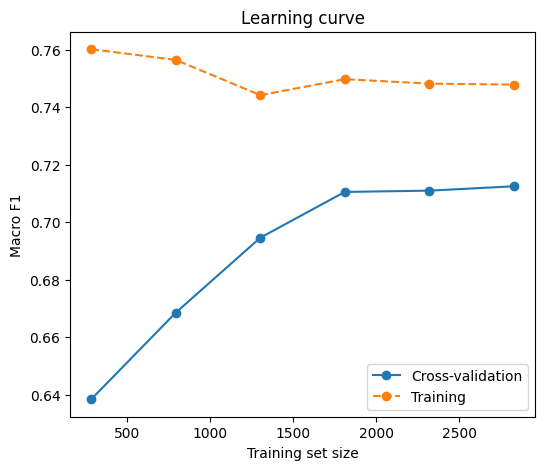

In [17]:
from sklearn.model_selection import learning_curve

sizes, train_sc, val_sc = learning_curve(
    best_model, X_train, y_train, cv=cv, scoring="f1_macro",
    train_sizes=np.linspace(0.1, 1.0, 6), n_jobs=-1
)

plt.figure(figsize=(6, 5))
plt.plot(sizes, val_sc.mean(axis=1), "o-", label="Cross-validation")
plt.plot(sizes, train_sc.mean(axis=1), "o--", label="Training")
plt.xlabel("Training set size")
plt.ylabel("Macro F1")
plt.title("Learning curve")
plt.legend()
plt.show()